## Pearson 连通性统计分析，作为 Prior-Guided Graph Learning (PGL) module 的设计理论基础

-**注：** 本代码在本地环境运行

本 notebook 对 NC / MCI / AD 三组受试者的 Pearson 通道连通性进行：
1. **分组加载**：从 `Neural_Markers.npz` 中读取各连通性矩阵
2. **组内统计**：计算各组的平均连通性矩阵
3. **组间比较**：置换检验比较组间差异
4. **可视化**：圆环图 + 3D connectome 图

In [38]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [52]:
# 路径配置
ASSESSMENT = 'Assess-01'
PARADIGM = 'resting state befor'
STATE = 'open eyes'

data_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature")
save_path = Path(r"C:\Python_Code\ADMamba\figs")
label_path = Path(r"F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI Label.xlsx")

PEARSON_DATA_ROOT = data_path.parent / "USTBMCI 128Hz Feature"
DATA_ROOT = PEARSON_DATA_ROOT / ASSESSMENT / PARADIGM / STATE
OUTPUT_DIR = save_path
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"数据目录不存在: {DATA_ROOT}")
print(f"DATA_ROOT = {DATA_ROOT}")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")
print(f"label_path = {label_path}")

# 20 通道标准 10-20 名称（与 coords 对应，数据为 20x20）
CH_NAMES = ['Fp1', 'Fp2', 'Fz', 'F3', 'F4', 'F7', 'F8', 'Cz', 'C3', 'C4', 'T7', 'T8', 'Pz', 'P3', 'P4', 'P7', 'P8', 'Oz', 'O1', 'O2']

# 连通性变量名（进入组统计 / 绘图 / 置换检验的 npz 键）
CONNECTIVITY_KEYS = [
    'corr_matrix_avg',
    'corr_matrix_avg_delta',
    'corr_matrix_avg_theta',
    'corr_matrix_avg_alpha',
    'corr_matrix_avg_beta',
    'corr_matrix_avg_gamma',
]

DATA_ROOT = F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI 128Hz Feature\Assess-01\resting state befor\open eyes
OUTPUT_DIR = C:\Python_Code\ADMamba\figs
label_path = F:\USTBMCI\预处理 后做 全局平均+坏道插值 有窗口筛查\USTBMCI Label.xlsx


### 加载 标签信息 各受试者连通性数据，按标签分组

In [53]:
df_label = pd.read_excel(label_path)
# 列索引：第2列(索引1)为英文名，第7列(索引6)为标签 1
name_col = df_label.columns[1]
label_col = df_label.columns[6]
label_map = dict(zip(df_label[name_col].astype(str).str.lower().str.strip(), df_label[label_col]))
print("标签统计:")
for lab in ['NC', 'MCI', 'AD']:
    n = (df_label[label_col] == lab).sum()
    print(f"  {lab}: {n} 人")
print(f"\n样本标签示例: {list(label_map.items())[:5]}")

标签统计:
  NC: 56 人
  MCI: 43 人
  AD: 12 人

样本标签示例: [('tianxiaolong', 'MCI'), ('wangyan', 'MCI'), ('yuandonghui', 'NC'), ('wanglijia', 'MCI'), ('wangjun', 'NC')]


In [54]:
def load_connectivity_by_group():
    """加载所有受试者的连通性数据，按 HC/MCI/AD 分组。"""
    groups = {'NC': {}, 'MCI': {}, 'AD': {}}
    subj_folders = [d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))]
    for subj in subj_folders:
        lab = label_map.get(subj.lower(), None)
        if lab not in groups:
            continue
        npz_path = os.path.join(DATA_ROOT, subj, "Neural_Markers.npz")
        if not os.path.exists(npz_path):
            continue
        data = np.load(npz_path, allow_pickle=True)
        subj_m = {k: np.asarray(data[k], dtype=float, copy=True) for k in CONNECTIVITY_KEYS if k in data}
        if 'corr_matrix_avg' in subj_m:
            np.fill_diagonal(subj_m['corr_matrix_avg'], 0.0)
        groups[lab][subj] = subj_m
    return groups

groups_data = load_connectivity_by_group()
for lab in ['NC', 'MCI', 'AD']:
    print(f"{lab}: {len(groups_data[lab])} 人")

NC: 56 人
MCI: 43 人
AD: 12 人


### 计算组间统计比较，绘制组间通道差异热力图

In [55]:
from statsmodels.stats.multitest import multipletests

def stack_matrices(group_dict, key):
    """将同一组内所有受试者的某连通性矩阵堆叠为 (n_subj, n_ch, n_ch)"""
    mats = [group_dict[s][key] for s in group_dict if key in group_dict[s]]
    return np.array(mats) if mats else None

def group_mean_std(group_dict, key):
    """计算组内均值和标准差"""
    stack = stack_matrices(group_dict, key)
    if stack is None:
        return None, None
    return np.nanmean(stack, axis=0), np.nanstd(stack, axis=0)

def permutation_test_edge(g1_stack, g2_stack, n_perm=1000):
    """对每条边做置换检验，返回 p 值矩阵"""
    n_ch = g1_stack.shape[1]
    pvals = np.ones((n_ch, n_ch))
    np.random.seed(42)
    for i in range(n_ch):
        for j in range(i+1, n_ch):
            a, b = g1_stack[:, i, j], g2_stack[:, i, j]
            obs = np.mean(a) - np.mean(b)
            combined = np.concatenate([a, b])
            n1, n2 = len(a), len(b)
            count = 0
            for _ in range(n_perm):
                perm = np.random.permutation(combined)
                diff = np.mean(perm[:n1]) - np.mean(perm[n1:])
                if np.abs(diff) >= np.abs(obs):
                    count += 1
            pvals[i, j] = pvals[j, i] = count / n_perm
    return pvals

def fisher_z_transform(r, eps=1e-7):
    """
    Pearson r -> Fisher Z
    避免 r=±1 导致 inf
    """
    r = np.clip(r, -1 + eps, 1 - eps)
    return np.arctanh(r)

def permutation_test_edge_corrected(
    g1_stack,
    g2_stack,
    n_perm=5000,
    use_fisher_z=True,
    fdr_alpha=0.05,
    random_state=42
):
    """
    对两组 Pearson 相关矩阵做逐边置换检验，并进行 FDR 校正。
    Parameters
    ----------
    g1_stack : ndarray, shape [N1, C, C]
        第1组连接矩阵，例如 HC
    g2_stack : ndarray, shape [N2, C, C]
        第2组连接矩阵，例如 MCI / AD
    n_perm : int
        置换次数
    use_fisher_z : bool
        是否对 Pearson r 做 Fisher Z 变换
    fdr_alpha : float
        FDR 显著性阈值
    random_state : int
        随机种子
    Returns
    -------
    results : dict
        diff_matrix      : 两组均值差异矩阵，mean(g1)-mean(g2)
        p_uncorrected    : 未校正 p 值矩阵
        p_fdr            : FDR 校正后的 p 值矩阵
        sig_fdr_mask     : FDR 校正后显著的布尔矩阵
        sig_diff_matrix  : 只保留显著边的差异矩阵
    """
    rng = np.random.default_rng(random_state)
    g1 = np.asarray(g1_stack, dtype=float)
    g2 = np.asarray(g2_stack, dtype=float)
    assert g1.ndim == 3 and g2.ndim == 3, "输入必须是 [N, C, C]"
    assert g1.shape[1:] == g2.shape[1:], "两组矩阵的通道数必须一致"
    if use_fisher_z:
        g1 = fisher_z_transform(g1)
        g2 = fisher_z_transform(g2)
    n1 = g1.shape[0]
    n2 = g2.shape[0]
    n_ch = g1.shape[1]
    diff_matrix = np.zeros((n_ch, n_ch))
    pvals = np.ones((n_ch, n_ch))
    edge_pvals = []
    edge_indices = []
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            a = g1[:, i, j]
            b = g2[:, i, j]
            a = a[~np.isnan(a)]
            b = b[~np.isnan(b)]
            if len(a) < 2 or len(b) < 2:
                continue
            obs = np.mean(a) - np.mean(b)
            diff_matrix[i, j] = diff_matrix[j, i] = obs
            combined = np.concatenate([a, b])
            n1_valid = len(a)
            count = 0
            for _ in range(n_perm):
                perm = rng.permutation(combined)
                perm_a = perm[:n1_valid]
                perm_b = perm[n1_valid:]
                diff_perm = np.mean(perm_a) - np.mean(perm_b)
                if np.abs(diff_perm) >= np.abs(obs):
                    count += 1
            # 避免 p=0
            p = (count + 1) / (n_perm + 1)
            pvals[i, j] = pvals[j, i] = p
            edge_pvals.append(p)
            edge_indices.append((i, j))
    # FDR 校正
    edge_pvals = np.array(edge_pvals)
    reject, pvals_fdr, _, _ = multipletests(
        edge_pvals,
        alpha=fdr_alpha,
        method="fdr_bh"
    )
    p_fdr_matrix = np.ones((n_ch, n_ch))
    sig_fdr_mask = np.zeros((n_ch, n_ch), dtype=bool)
    for idx, (i, j) in enumerate(edge_indices):
        p_fdr_matrix[i, j] = p_fdr_matrix[j, i] = pvals_fdr[idx]
        sig_fdr_mask[i, j] = sig_fdr_mask[j, i] = reject[idx]
    sig_diff_matrix = diff_matrix * sig_fdr_mask
    return {
        "diff_matrix": diff_matrix,
        "p_uncorrected": pvals,
        "p_fdr": p_fdr_matrix,
        "sig_fdr_mask": sig_fdr_mask,
        "sig_diff_matrix": sig_diff_matrix,
    }

In [56]:
# 存储各组均值和组间差异
GROUPS = ['NC', 'MCI', 'AD']
MIN_GROUP_SIZE = 3
N_PERM = 500
PERM_EDGE_TEST_MODE = 'fdr_corrected'  # 'uncorrected' | 'fdr_corrected'

group_means = {lab: {} for lab in GROUPS}
group_diff_nc_mci, group_diff_nc_ad, group_diff_mci_ad = {}, {}, {}
pval_nc_mci, pval_nc_ad, pval_mci_ad = {}, {}, {}

GROUP_PAIRS = [
    ('NC', 'MCI', group_diff_nc_mci, pval_nc_mci),
    ('NC', 'AD',  group_diff_nc_ad,  pval_nc_ad),
    ('MCI', 'AD', group_diff_mci_ad, pval_mci_ad),
]


def _pairwise_pvals(g1_stack, g2_stack):
    if PERM_EDGE_TEST_MODE == 'uncorrected':
        return permutation_test_edge(g1_stack, g2_stack, n_perm=N_PERM)
    if PERM_EDGE_TEST_MODE == 'fdr_corrected':
        return permutation_test_edge_corrected(
            g1_stack, g2_stack, n_perm=N_PERM, use_fisher_z=True, fdr_alpha=0.05,
        )['p_uncorrected']
    raise ValueError(
        "PERM_EDGE_TEST_MODE 须为 'uncorrected' 或 'fdr_corrected'，"
        f"当前: {PERM_EDGE_TEST_MODE!r}")


for key in CONNECTIVITY_KEYS:
    stacks = {lab: stack_matrices(groups_data[lab], key) for lab in GROUPS}
    for lab in GROUPS:
        mean_mat, _ = group_mean_std(groups_data[lab], key)
        if mean_mat is not None:
            group_means[lab][key] = mean_mat

    for g1, g2, diff_dict, pval_dict in GROUP_PAIRS:
        s1, s2 = stacks[g1], stacks[g2]
        if s1 is None or s2 is None:
            continue
        if s1.shape[0] < MIN_GROUP_SIZE or s2.shape[0] < MIN_GROUP_SIZE:
            continue
        diff_dict[key] = group_means[g1][key] - group_means[g2][key]
        pval_dict[key] = _pairwise_pvals(s1, s2)

print('各组平均连通性矩阵及组间差异已计算完成')

各组平均连通性矩阵及组间差异已计算完成


In [57]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ---------- 可配置参数 ----------
PLOT_CONN_KEY = 'corr_matrix_avg'
PLOT_FONT = 'Times New Roman'
FONT_TITLE = 12          # 图标题字号
FONT_AXIS_LABEL = 30     # 横纵坐标标题字号
FONT_TICK = 20            # 横纵坐标刻度字号
FONT_LEGEND = 20          # 图例字号
PVAL_ALPHA = 0.05

GROUP_PAIRS = [
    (group_diff_nc_mci, pval_nc_mci, 'NC_vs_MCI'),
    (group_diff_nc_ad,  pval_nc_ad,  'NC_vs_AD'),
    (group_diff_mci_ad, pval_mci_ad, 'MCI_vs_AD'),
]

_paradigm_tag = PARADIGM.split()[-1]
_perm_mode = globals().get('PERM_EDGE_TEST_MODE', 'uncorrected')
_pval_plot_title = (
    'FDR (BH) q ≤ 0.05' if _perm_mode == 'fdr_corrected' else 'p ≤ 0.05 (未校正)')

plt.rcParams.update({'font.family': PLOT_FONT, 'font.serif': [PLOT_FONT]})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def _build_edge_rows(conn_key, diff, pvals):
    return [
        {
            'Feature': conn_key,
            'Ch1': CH_NAMES[i],
            'Ch2': CH_NAMES[j],
            'Diff': diff[i, j],
            'p': pvals[i, j],
            'Sig': pvals[i, j] < PVAL_ALPHA,
        }
        for i in range(len(CH_NAMES))
        for j in range(i + 1, len(CH_NAMES))
    ]


def _plot_significance_heatmap(pvals, pair_name, save_path):
    n_ch = len(CH_NAMES)
    pvals_plot = pvals.copy()
    np.fill_diagonal(pvals_plot, np.nan)
    binary = np.where(pvals_plot <= PVAL_ALPHA, 1.0, 0.0)
    np.fill_diagonal(binary, np.nan)

    fig, ax = plt.subplots(figsize=(10, 8), facecolor='white')
    ax.set_facecolor('white')
    cmap_binary = ListedColormap(['white', '#c62828'])
    cmap_binary.set_bad(color='white')
    ax.imshow(
        binary, cmap=cmap_binary, vmin=0, vmax=1, aspect='equal',
        interpolation='nearest', origin='upper',
    )
    ax.set_xticks(range(n_ch))
    ax.set_yticks(range(n_ch))
    ax.set_xticklabels(CH_NAMES, rotation=45, ha='right', fontsize=FONT_TICK)
    ax.set_yticklabels(CH_NAMES, fontsize=FONT_TICK)
    ax.set_xticks(np.arange(-0.5, n_ch, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_ch, 1), minor=True)
    ax.grid(which='minor', color='#9e9e9e', linestyle='-', linewidth=0.5, alpha=0.85)
    ax.tick_params(which='minor', bottom=False, left=False, length=0)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_edgecolor('#666666')

    ax.set_xlabel('Channel', fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel('Channel', fontsize=FONT_AXIS_LABEL)
    # ax.set_title(
    #     f'{PLOT_CONN_KEY}  |  {_pval_plot_title} ({pair_name})',
    #     fontsize=FONT_TITLE, fontweight='bold', pad=12,
    # )
    # leg = ax.legend(
    #     handles=[
    #         Patch(facecolor='#fafafa', edgecolor='#bdbdbd', linewidth=0.6,
    #               label=f'Not significant (p > {PVAL_ALPHA})'),
    #         Patch(facecolor='#c62828', edgecolor='#5c0000', linewidth=0.6,
    #               label=f'Significant (p ≤ {PVAL_ALPHA})'),
    #     ],
    #     loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0,
    #     frameon=True, prop={'family': PLOT_FONT, 'size': FONT_LEGEND}, title='Legend',
    # )
    # leg.get_title().set_fontsize(FONT_LEGEND)
    # leg.get_frame().set_facecolor('white')

    plt.tight_layout()
    # plt.savefig(save_path, format='svg', bbox_inches='tight', bbox_extra_artists=[leg], facecolor='white')
    plt.savefig(save_path, format='svg', bbox_inches='tight', facecolor='white')
    plt.close()


for diff_dict, pval_dict, pair_name in GROUP_PAIRS:
    saved_img = False
    if PLOT_CONN_KEY in pval_dict:
        img_path = OUTPUT_DIR / f'{PLOT_CONN_KEY}_{_paradigm_tag}_{pair_name}_pval_heatmap.svg'
        _plot_significance_heatmap(pval_dict[PLOT_CONN_KEY], pair_name, img_path)
        saved_img = True

    excel_sheets = {}
    for conn_key in CONNECTIVITY_KEYS:
        if conn_key not in diff_dict or conn_key not in pval_dict:
            continue
        rows = _build_edge_rows(conn_key, diff_dict[conn_key], pval_dict[conn_key])
        if rows:
            excel_sheets[conn_key[:31]] = pd.DataFrame(rows)

    # excel_msg = '无 Excel 数据（跳过）'
    # if excel_sheets:
    #     excel_path = OUTPUT_DIR / f'{_paradigm_tag}_{pair_name}_connectivity_stats.xlsx'
    #     with pd.ExcelWriter(excel_path) as writer:
    #         for sheet_name, df in excel_sheets.items():
    #             df.to_excel(writer, sheet_name=sheet_name, index=False)
    #     excel_msg = excel_path.name

    img_msg = '1 张图' if saved_img else '0 张图'
    print(f'已保存: {pair_name} -> {img_msg}')


已保存: NC_vs_MCI -> 1 张图
已保存: NC_vs_AD -> 1 张图
已保存: MCI_vs_AD -> 1 张图


### 计算受试者的平均pearson连接强度，绘制小提琴对比图

In [17]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy import stats


def mask_cross_region_connectivity(mat, ch_names, region_map, region_a, region_b):
    """只保留 region_a 与 region_b 之间通道对的连接，其余非对角元置 0。"""
    names = np.asarray(ch_names, dtype=object)
    in_a = np.isin(names, region_map[region_a])
    in_b = np.isin(names, region_map[region_b])
    cross = np.logical_or(np.outer(in_a, in_b), np.outer(in_b, in_a))
    np.fill_diagonal(cross, False)
    out = np.array(mat, dtype=float, copy=True)
    out[~cross] = 0.0
    np.fill_diagonal(out, 0.0)
    return out


def cross_region_edge_indices(ch_names, region_map, region_a, region_b):
    """上三角中 region_a 与 region_b 之间的跨区边 (i, j)，满足 i < j。"""
    names = np.asarray(ch_names, dtype=object)
    in_a = np.isin(names, region_map[region_a])
    in_b = np.isin(names, region_map[region_b])
    n = len(ch_names)
    iu = np.triu_indices(n, k=1)
    i, j = iu[0], iu[1]
    cross = (in_a[i] & in_b[j]) | (in_b[i] & in_a[j])
    return i[cross], j[cross]


def cross_region_subject_stats(mat, ch_names, region_map, region_a, region_b, nonzero_eps=1e-12):
    """单被试：两脑区跨区子图的节点数、边数及连接强度（仅统计跨区边，先掩蔽全图再传入亦可）。
    若 region_a == region_b（如全脑 'Whole Brain'），则统计该区内上三角无向边，n_edges_possible = n(n-1)/2。
    """
    mat = np.asarray(mat, dtype=float)
    names = np.asarray(ch_names, dtype=object)
    in_a = np.isin(names, region_map[region_a])
    in_b = np.isin(names, region_map[region_b])
    if region_a == region_b:
        n_sel = int(np.logical_and(in_a, in_b).sum())
        n_nodes_regions = n_sel
        n_edges_possible = n_sel * (n_sel - 1) // 2 if n_sel >= 2 else 0
    else:
        n_nodes_regions = int(in_a.sum() + in_b.sum())
        n_edges_possible = int(in_a.sum() * in_b.sum())
    i, j = cross_region_edge_indices(ch_names, region_map, region_a, region_b)
    w = mat[i, j].astype(float)
    nz = np.abs(w) > nonzero_eps
    n_edges_nonzero = int(np.sum(nz))
    active = set()
    for ii, jj, ok in zip(i, j, nz):
        if not ok:
            continue
        active.add(int(ii))
        active.add(int(jj))
    n_nodes_active = len(active)
    return {
        'n_nodes_regions': n_nodes_regions,
        'n_nodes_active': n_nodes_active,
        'n_edges_possible': n_edges_possible,
        'n_edges_nonzero': n_edges_nonzero,
        'edge_density': (n_edges_nonzero / n_edges_possible) if n_edges_possible else np.nan,
        'mean_r_all_pairs': float(np.mean(w)) if n_edges_possible else np.nan,
        'mean_abs_r_all_pairs': float(np.mean(np.abs(w))) if n_edges_possible else np.nan,
    }


def collect_cross_region_stats_long(groups_data, conn_key, ch_names, region_map, region_a, region_b,
                                    abs_before_stats=False):
    """所有被试长表：一行一个被试，指标见 cross_region_subject_stats。
    abs_before_stats：若为 True，在统计前对跨区掩蔽后的矩阵全体取绝对值（|r| 版）。"""
    rows = []
    for group in ['HC', 'MCI', 'AD']:
        for subj, d in groups_data[group].items():
            if conn_key not in d:
                continue
            mat = mask_cross_region_connectivity(
                d[conn_key], ch_names, region_map, region_a, region_b)
            if abs_before_stats:
                mat = np.abs(mat)
            st = cross_region_subject_stats(mat, ch_names, region_map, region_a, region_b)
            rows.append({'组别': group, '被试': subj, **st})
    return pd.DataFrame(rows)


def summarize_cross_region_by_group(df_long):
    """按组别汇总被试水平指标的 mean / std / median / sem。"""
    num_cols = [c for c in df_long.columns if c not in ('组别', '被试')]
    rows = []
    for lab in ['HC', 'MCI', 'AD']:
        sub = df_long[df_long['组别'] == lab]
        r = {'组别': lab, 'n_subj': len(sub)}
        for c in num_cols:
            x = pd.to_numeric(sub[c], errors='coerce')
            r[f'{c}_mean'] = float(x.mean()) if len(x) else np.nan
            r[f'{c}_std'] = float(x.std(ddof=0)) if len(x) else np.nan
            r[f'{c}_median'] = float(x.median()) if len(x) else np.nan
            r[f'{c}_sem'] = float(x.std(ddof=0) / np.sqrt(len(x))) if len(x) > 0 else np.nan
        rows.append(r)
    return pd.DataFrame(rows)


def kruskal_three_groups(df_long, metric_col):
    """三组 Kruskal-Wallis；metric 为被试水平一列。"""
    sub = [df_long.loc[df_long['组别'] == g, metric_col].dropna().values for g in ['HC', 'MCI', 'AD']]
    sub = [x for x in sub if len(x) > 0]
    if len(sub) < 2:
        return {'metric': metric_col, 'H': np.nan, 'p': np.nan, 'note': '<2 groups with data'}
    try:
        H, p = stats.kruskal(*sub)
        return {'metric': metric_col, 'H': float(H), 'p': float(p), 'note': ''}
    except ValueError as e:
        # 例如三组该指标完全相同（全 0、无秩变异）时 scipy 会报错
        return {'metric': metric_col, 'H': np.nan, 'p': np.nan, 'note': str(e)}


def pairwise_mannwhitney_long(df_long, metric_col):
    """三组两两 Mann-Whitney U（双尾）。"""
    pairs = [('HC', 'MCI'), ('HC', 'AD'), ('MCI', 'AD')]
    rows = []
    for a, b in pairs:
        xa = df_long.loc[df_long['组别'] == a, metric_col].dropna()
        xb = df_long.loc[df_long['组别'] == b, metric_col].dropna()
        if len(xa) < 1 or len(xb) < 1:
            rows.append({'metric': metric_col, 'g1': a, 'g2': b, 'U': np.nan, 'p': np.nan, 'note': 'empty'})
            continue
        try:
            U, p = stats.mannwhitneyu(xa, xb, alternative='two-sided')
            rows.append({'metric': metric_col, 'g1': a, 'g2': b, 'U': float(U), 'p': float(p), 'note': ''})
        except ValueError as e:
            rows.append({'metric': metric_col, 'g1': a, 'g2': b, 'U': np.nan, 'p': np.nan, 'note': str(e)})
    return pd.DataFrame(rows)

In [18]:
# 连通性统计（边数、节点数、强度；组间 Kruskal / 两两 Mann-Whitney）
# 指标均为被试内连通矩阵上三角（不含对角），再按 HC/MCI/AD 汇总。
kw_metrics = [
    'n_edges_nonzero', 'edge_density', 'n_nodes_active',
    'mean_r_all_pairs', 'mean_abs_r_all_pairs',
]

# (标签, abs_before_stats)：signed=保留符号；abs_r=统计前对矩阵取 |r|
CROSS_REGION_STAT_VARIANTS = [('signed', False), ('abs_r', True)]

# collect_cross_region_stats_long 内部使用的默认通道范围（即全部 CH_NAMES）
_default_region_map = {'default': list(CH_NAMES)}

# 结果存入变量，键为 (conn_key, variant_label)
cross_region_stats = {}

for conn_key in CONNECTIVITY_KEYS:
    for variant_label, use_abs in CROSS_REGION_STAT_VARIANTS:
        df_cross_subj = collect_cross_region_stats_long(
            groups_data, conn_key, CH_NAMES, _default_region_map, 'default', 'default',
            abs_before_stats=use_abs)
        if df_cross_subj.empty:
            print(f'跳过 {conn_key} [{variant_label}]：无数据')
            continue
        df_cross_group = summarize_cross_region_by_group(df_cross_subj)
        kw_rows = [kruskal_three_groups(df_cross_subj, m) for m in kw_metrics if m in df_cross_subj.columns]
        mw_list = [pairwise_mannwhitney_long(df_cross_subj, m) for m in kw_metrics if m in df_cross_subj.columns]
        key = (conn_key, variant_label)
        cross_region_stats[key] = {
            'per_subject': df_cross_subj,
            'by_group': df_cross_group,
            'kruskal': pd.DataFrame(kw_rows),
            'pairwise_mannwhitney': pd.concat(mw_list, axis=0, ignore_index=True) if mw_list else pd.DataFrame(),
        }
        preview_cols = ['组别', 'n_subj', 'n_edges_nonzero_mean', 'edge_density_mean',
                        'n_nodes_active_mean', 'mean_abs_r_all_pairs_mean']
        prev = [c for c in preview_cols if c in df_cross_group.columns]
        print(f'{conn_key}  [{variant_label}]')
        print(df_cross_group[prev].to_string(index=False) if prev else df_cross_group.to_string(index=False))

print(f'共计算 {len(cross_region_stats)} 组统计，结果保存在 cross_region_stats 变量中')

corr_matrix_avg  [signed]
 组别  n_subj  n_edges_nonzero_mean  edge_density_mean  n_nodes_active_mean  mean_abs_r_all_pairs_mean
 NC      56                 190.0                1.0                 20.0                   0.305523
MCI      43                 190.0                1.0                 20.0                   0.325041
 AD      12                 190.0                1.0                 20.0                   0.330114
corr_matrix_avg  [abs_r]
 组别  n_subj  n_edges_nonzero_mean  edge_density_mean  n_nodes_active_mean  mean_abs_r_all_pairs_mean
 NC      56                 190.0                1.0                 20.0                   0.305523
MCI      43                 190.0                1.0                 20.0                   0.325041
 AD      12                 190.0                1.0                 20.0                   0.330114
corr_matrix_avg_delta  [signed]
 组别  n_subj  n_edges_nonzero_mean  edge_density_mean  n_nodes_active_mean  mean_abs_r_all_pairs_mean
 NC     

In [19]:
# 横轴频段顺序与 npz 键名映射
FREQUENCY_BAND_SPECS: list[tuple[str, str]] = [
    ("delta", "Delta"),
    ("theta", "Theta"),
    ("alpha", "Alpha"),
    ("beta", "Beta"),
    ("gamma", "Gamma"),
    ("full", "Full"),
]

_BAND_PREFIX_BY_ID: dict[str, str] = {
    "delta": "corr_matrix_avg_delta",
    "theta": "corr_matrix_avg_theta",
    "alpha": "corr_matrix_avg_alpha",
    "beta": "corr_matrix_avg_beta",
    "gamma": "corr_matrix_avg_gamma",
}

CATEGORIES = ["HC", "MCI", "AD"]
COLORS_MAP = {"HC": "lightblue", "MCI": "lightyellow", "AD": "lightcoral"}


def conn_key_for_band(band_id: str) -> str:
    if band_id == "full":
        return "corr_matrix_avg"
    return _BAND_PREFIX_BY_ID[band_id]


def build_mean_r_plot_data_from_stats(
    cross_region_stats: dict,
    *,
    variant_label: str = "signed",
    metric_col: str = "mean_r_all_pairs",
) -> dict[str, dict[str, np.ndarray]]:
    """从 cross_region_stats 的 per_subject 表提取各频段指标，供小提琴图使用。"""
    plot_data = {bid: {c: np.array([], dtype=float) for c in CATEGORIES} for bid, _ in FREQUENCY_BAND_SPECS}
    for band_id, _ in FREQUENCY_BAND_SPECS:
        conn_key = conn_key_for_band(band_id)
        key = (conn_key, variant_label)
        if key not in cross_region_stats:
            continue
        df = cross_region_stats[key]["per_subject"]
        if metric_col not in df.columns:
            continue
        for lab in CATEGORIES:
            vals = pd.to_numeric(df.loc[df["组别"] == lab, metric_col], errors="coerce").dropna().values
            plot_data[band_id][lab] = np.asarray(vals, dtype=float)
    return plot_data


def plot_frequency_band_violin(
    plot_data: dict[str, dict[str, np.ndarray]],
    *,
    metric_label: str = "mean_r_all_pairs",
    title: str | None = None,
    save_path: Path | None = None,
    figsize=(14, 7),
    font_family: str = "Times New Roman",
    font_title: int = 14,
    font_axis_label: int = 12,
    font_tick: int = 11,
    font_legend: int = 10,
):
    """横轴为频段 Delta→Theta→Alpha→Beta→Gamma→Full，每组 HC/MCI/AD 小提琴 + 箱线。"""
    plt.rcParams.update({
        "font.family": font_family,
        "font.serif": [font_family],
        "axes.unicode_minus": False,
    })

    band_order = [bid for bid, _ in FREQUENCY_BAND_SPECS]
    band_labels = dict(FREQUENCY_BAND_SPECS)
    if title is None:
        title = f"{metric_label} (by frequency band)"

    positions: list[float] = []
    data_to_plot: list[np.ndarray] = []
    band_centers: list[float] = []
    labels: list[str] = []
    x_pos = 1.0

    for band_id in band_order:
        band_start = x_pos
        band_has_data = False
        for cat in CATEGORIES:
            cat_data = plot_data[band_id][cat]
            if cat_data.size > 0:
                positions.append(x_pos)
                data_to_plot.append(cat_data)
                x_pos += 1.0
                band_has_data = True
        if band_has_data:
            band_centers.append((band_start + x_pos - 1.0) / 2.0)
            labels.append(band_labels[band_id])
        x_pos += 0.5

    if not data_to_plot:
        raise ValueError("无有效数据可绘制")

    fig, ax = plt.subplots(figsize=figsize)
    parts = ax.violinplot(
        data_to_plot,
        positions=positions,
        widths=0.6,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    colors: list[str] = []
    for band_id in band_order:
        for cat in CATEGORIES:
            if plot_data[band_id][cat].size > 0:
                colors.append(COLORS_MAP[cat])

    for pc, color in zip(parts["bodies"], colors):
        pc.set_facecolor(color)
        pc.set_alpha(0.7)

    box_width = 0.4
    for pos, data in zip(positions, data_to_plot):
        if data.size == 0:
            continue
        q1, median, q3 = np.percentile(data, [25, 50, 75])
        iqr = q3 - q1
        lower_whisker = max(q1 - 1.5 * iqr, np.min(data))
        upper_whisker = min(q3 + 1.5 * iqr, np.max(data))
        lower_pos = np.min(data[data >= lower_whisker])
        upper_pos = np.max(data[data <= upper_whisker])
        mean_val = float(np.mean(data))

        rect = plt.Rectangle(
            (pos - box_width / 2, q1),
            box_width,
            q3 - q1,
            fill=False,
            edgecolor="black",
            linewidth=1.5,
            zorder=10,
        )
        ax.add_patch(rect)
        ax.plot([pos - box_width / 2, pos + box_width / 2], [median, median], "k-", linewidth=2, zorder=11)
        ax.plot(
            [pos - box_width / 2, pos + box_width / 2],
            [mean_val, mean_val],
            linestyle="--",
            color="darkgreen",
            linewidth=2,
            zorder=12,
        )
        ax.plot([pos, pos], [q1, lower_pos], "k-", linewidth=1.5, zorder=10)
        ax.plot([pos, pos], [q3, upper_pos], "k-", linewidth=1.5, zorder=10)
        ww = 0.15
        ax.plot([pos - ww / 2, pos + ww / 2], [lower_pos, lower_pos], "k-", linewidth=1.5, zorder=10)
        ax.plot([pos - ww / 2, pos + ww / 2], [upper_pos, upper_pos], "k-", linewidth=1.5, zorder=10)

        outliers = data[(data < lower_whisker) | (data > upper_whisker)]
        if outliers.size > 0:
            ax.scatter(
                [pos] * len(outliers),
                outliers,
                s=30,
                color="black",
                marker="o",
                edgecolors="white",
                linewidths=0.5,
                zorder=12,
            )

    x_pos_current = 1.0
    for band_id in band_order:
        band_categories = [c for c in CATEGORIES if plot_data[band_id][c].size > 0]
        band_data_dict = {c: plot_data[band_id][c] for c in band_categories}
        for i, cat1 in enumerate(band_categories):
            for cat2 in band_categories[i + 1 :]:
                d1, d2 = band_data_dict[cat1], band_data_dict[cat2]
                if d1.size == 0 or d2.size == 0:
                    continue
                try:
                    _, p_value = stats.mannwhitneyu(d1, d2, alternative="two-sided")
                    sig_label = (
                        "***" if p_value < 0.001 else "**" if p_value < 0.01 else "*" if p_value < 0.05 else "ns"
                    )
                    if sig_label == "ns":
                        continue
                    all_values = np.concatenate([d1, d2])
                    y_max, y_min = float(np.max(all_values)), float(np.min(all_values))
                    y_range = y_max - y_min if y_max > y_min else (abs(y_max) * 0.1 + 1e-9)
                    line_top = max(float(np.max(d1)), float(np.max(d2))) + y_range * 0.05
                    line_bottom = line_top - y_range * 0.02
                    text_y = line_top + y_range * 0.02
                    cat1_pos = x_pos_current + band_categories.index(cat1)
                    cat2_pos = x_pos_current + band_categories.index(cat2)
                    ax.plot([cat1_pos, cat2_pos], [line_top, line_top], "k-", linewidth=1.5, alpha=0.7)
                    ax.plot([cat1_pos, cat1_pos], [line_bottom, line_top], "k-", linewidth=1.5, alpha=0.7)
                    ax.plot([cat2_pos, cat2_pos], [line_bottom, line_top], "k-", linewidth=1.5, alpha=0.7)
                    ax.text(
                        (cat1_pos + cat2_pos) / 2,
                        text_y,
                        sig_label,
                        ha="center",
                        va="bottom",
                        fontsize=12,
                        fontweight="bold",
                        fontfamily="Times New Roman",
                    )
                except Exception:
                    pass
        x_pos_current += len(band_categories) + 0.5

    ax.set_xticks(band_centers)
    ax.set_xticklabels(labels, rotation=0, ha="center", fontsize=font_tick, fontfamily=font_family)
    ax.tick_params(axis="y", labelsize=font_tick)
    for lbl in ax.get_yticklabels():
        lbl.set_fontfamily(font_family)
    ax.set_title(title, fontsize=font_title, fontweight="bold", fontfamily=font_family)
    ax.set_ylabel(metric_label, fontsize=font_axis_label, fontfamily=font_family)
    ax.set_xlabel("Frequency band", fontsize=font_axis_label, fontfamily=font_family)

    legend_handles = [Patch(facecolor=COLORS_MAP[c], alpha=0.7, label=c) for c in CATEGORIES]
    legend_handles += [
        Line2D([0], [0], color="black", linewidth=2, linestyle="-", label="Median"),
        Line2D([0], [0], color="darkgreen", linewidth=2, linestyle="--", label="Mean"),
    ]
    ax.legend(handles=legend_handles, loc="upper right", prop={"family": font_family, "size": font_legend})
    ax.grid(True, alpha=0.3, linestyle="--", axis="y")
    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=600, bbox_inches="tight")
        print(f"已保存: {save_path}")
    plt.show()

已保存: C:\Python_Code\ADMamba\figs\mean_r_all_pairs_violin_by_frequency_befor.png


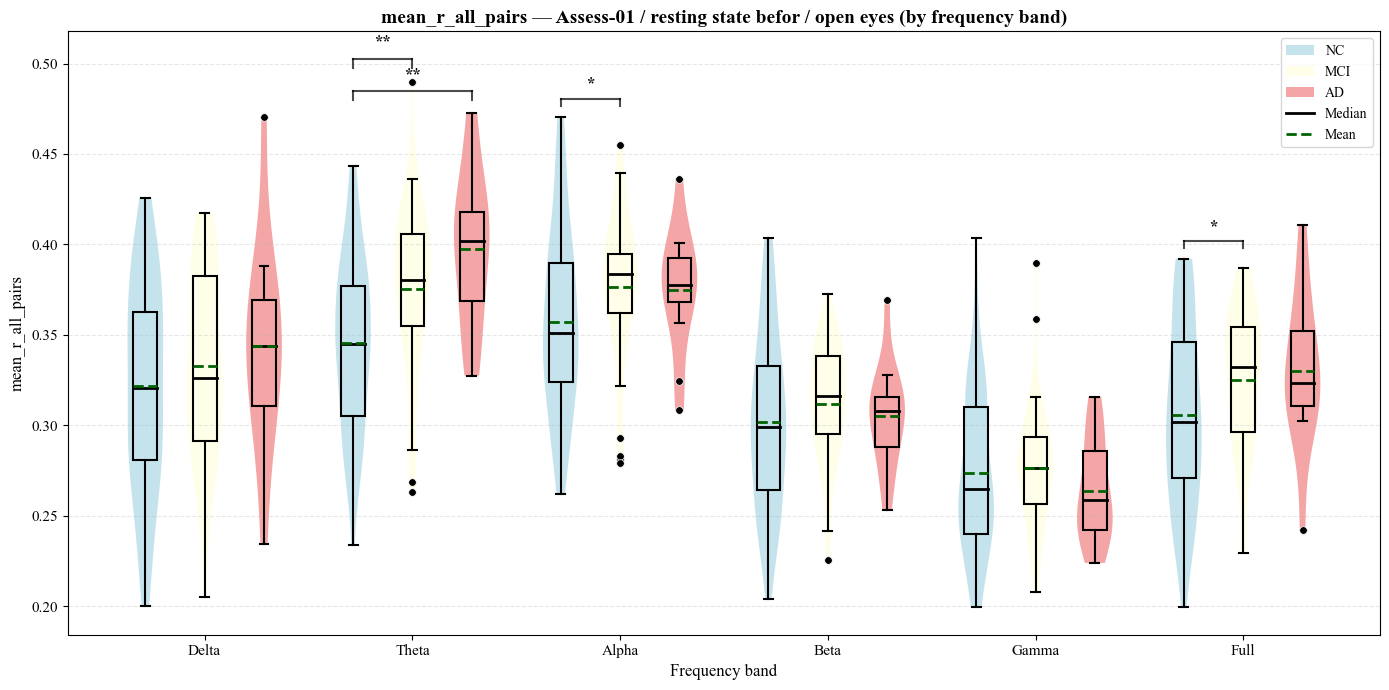

In [20]:
VIOLIN_STAT_VARIANT = "abs_r"

# ---------- 小提琴图字体配置（Times New Roman）----------
VIOLIN_FONT_FAMILY = "Times New Roman"
VIOLIN_FONT_TITLE = 14          # 图标题字号
VIOLIN_FONT_AXIS_LABEL = 12     # 横纵坐标标题字号
VIOLIN_FONT_TICK = 11           # 横纵坐标刻度字号
VIOLIN_FONT_LEGEND = 10         # 图例字号


violin_plot_data = build_mean_r_plot_data_from_stats(
    cross_region_stats, variant_label=VIOLIN_STAT_VARIANT, metric_col="mean_r_all_pairs")
has_data = any(arr.size > 0 for band in violin_plot_data.values() for arr in band.values())
if not has_data:
    print(f"[提示] cross_region_stats 中无 mean_r_all_pairs（{VIOLIN_STAT_VARIANT}）数据，无法绘制小提琴图。")
else:
    _paradigm_tag = PARADIGM.split()[-1]
    out_png = OUTPUT_DIR / f"mean_r_all_pairs_violin_by_frequency_{_paradigm_tag}.png"
    plot_frequency_band_violin(
        violin_plot_data,
        metric_label="mean_r_all_pairs",
        title=f"mean_r_all_pairs — {ASSESSMENT} / {PARADIGM} / {STATE} (by frequency band)",
        save_path=out_png,
        font_family=VIOLIN_FONT_FAMILY,
        font_title=VIOLIN_FONT_TITLE,
        font_axis_label=VIOLIN_FONT_AXIS_LABEL,
        font_tick=VIOLIN_FONT_TICK,
        font_legend=VIOLIN_FONT_LEGEND,
    )

### 计算不同不同频带功率在人群之间的Effect Size（效应量）

In [ ]:
# 计算不同不同频带功率在人群之间的Effect Size（效应量）
from sklearn.utils import resample

def cohens_d(x1, x2):
    """
    Calculate Cohen's d effect size.
    Parameters
    ----------
    x1 : array-like
        Group 1 data
    x2 : array-like
        Group 2 data
    Returns
    -------
    d : float
        Cohen's d
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)
    n1 = len(x1)
    n2 = len(x2)
    mean1 = np.mean(x1)
    mean2 = np.mean(x2)
    std1 = np.std(x1, ddof=1)
    std2 = np.std(x2, ddof=1)
    # pooled standard deviation
    pooled_std = np.sqrt(
        ((n1 - 1) * std1**2 + (n2 - 1) * std2**2)
        / (n1 + n2 - 2)
    )
    d = (mean1 - mean2) / pooled_std
    return d

def hedges_g(x1, x2):
    """
    Calculate Hedges' g effect size.
    Parameters
    ----------
    x1 : array-like
        Group 1 data
    x2 : array-like
        Group 2 data
    Returns
    -------
    g : float
        Hedges' g
    """
    x1 = np.asarray(x1)
    x2 = np.asarray(x2)
    n1 = len(x1)
    n2 = len(x2)
    mean1 = np.mean(x1)
    mean2 = np.mean(x2)
    std1 = np.std(x1, ddof=1)
    std2 = np.std(x2, ddof=1)
    pooled_std = np.sqrt(
        ((n1 - 1) * std1**2 + (n2 - 1) * std2**2)
        / (n1 + n2 - 2)
    )
    d = (mean1 - mean2) / pooled_std
    # correction factor
    correction = 1 - (3 / (4 * (n1 + n2) - 9))
    g = correction * d
    return g

def bootstrap_hedges_g(x1, x2, n_boot=5000):
    values = []
    for _ in range(n_boot):
        b1 = resample(x1)
        b2 = resample(x2)
        values.append(hedges_g(b1, b2))
    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)
    return np.mean(values), (lower, upper)

In [ ]:
# 按各频带 × 人群两两，计算 mean_r_all_pairs 的效应量并保存为 Excel
# 需先运行连通性统计 cell（cross_region_stats）及上方效应量函数 cell
EFFECT_STAT_VARIANT = VIOLIN_STAT_VARIANT if "VIOLIN_STAT_VARIANT" in globals() else "signed"
pairwise_groups = [("HC", "MCI"), ("HC", "AD"), ("MCI", "AD")]
n_boot_effects = 5000

if "cross_region_stats" not in globals() or not cross_region_stats:
    print("[提示] 请先运行上方连通性统计 cell。")
else:
    effect_plot_data = build_mean_r_plot_data_from_stats(
        cross_region_stats, variant_label=EFFECT_STAT_VARIANT, metric_col="mean_r_all_pairs")
    has_data = any(arr.size > 0 for band in effect_plot_data.values() for arr in band.values())
    if not has_data:
        print(f"[提示] cross_region_stats 中无 mean_r_all_pairs（{EFFECT_STAT_VARIANT}）数据，无法计算效应量。")
    else:
        rows_es = []
        for band_id, band_label in FREQUENCY_BAND_SPECS:
            band_data = effect_plot_data[band_id]
            for g1, g2 in pairwise_groups:
                xa, xb = band_data[g1], band_data[g2]
                na, nb = int(xa.size), int(xb.size)
                rec = {
                    "stat_variant": EFFECT_STAT_VARIANT,
                    "assessment": ASSESSMENT,
                    "paradigm": PARADIGM,
                    "state": STATE,
                    "frequency_band_id": band_id,
                    "frequency_band": band_label,
                    "group1": g1,
                    "group2": g2,
                    "n_group1": na,
                    "n_group2": nb,
                }
                if na < 2 or nb < 2:
                    rec["cohens_d"] = np.nan
                    rec["hedges_g"] = np.nan
                    rec["hedges_g_bootstrap_mean"] = np.nan
                    rec["hedges_g_ci95_lower"] = np.nan
                    rec["hedges_g_ci95_upper"] = np.nan
                else:
                    rec["cohens_d"] = float(cohens_d(xa, xb))
                    rec["hedges_g"] = float(hedges_g(xa, xb))
                    bm, ci = bootstrap_hedges_g(xa, xb, n_boot=n_boot_effects)
                    rec["hedges_g_bootstrap_mean"] = float(bm)
                    rec["hedges_g_ci95_lower"] = float(ci[0])
                    rec["hedges_g_ci95_upper"] = float(ci[1])
                rows_es.append(rec)

        df_effect_sizes = pd.DataFrame(rows_es)
        _paradigm_tag = PARADIGM.split()[-1]
        effect_sizes_excel = OUTPUT_DIR / f"effect_sizes_mean_r_pairwise_{_paradigm_tag}_{EFFECT_STAT_VARIANT}.xlsx"
        df_effect_sizes.to_excel(effect_sizes_excel, index=False)
        print(f"已保存效应量表: {effect_sizes_excel}")